# MVP4 — NB02 Rain-pulse exploratory contrasts (2019–2021 only)
**Question.** After heavy rain, does the share of FDI anomalies (pixels above the date's own p99) rise in stable water within 2 km of river/canal outlets, relative to water > 3 km from outlets, compared with a dry reference date?
**Contrast per pair:** DiD = (source: event − reference) − (far: event − reference). Pre-stated direction: DiD > 0. The same contrast on B4 (red) is the turbidity check.
**Scope:** exploratory period only (a guard refuses any date after 2021). p-values are descriptive. S2 only; everything is computed server-side as zone statistics (no rasters downloaded).
**Inputs from NB01** (`results/mvp4_feasibility`): `outlets_merged_<site>.csv`, `mvp4_feasibility_summary_p90.json`.
**Terminology:** floating marine-debris / macroplastic aggregation *candidates*; nothing here identifies material.

In [21]:
pip install pystac_client --q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.1 MB/s eta 0:00:00


In [ ]:
# MVP4-20 | Setup: Drive, paths, Earth Engine, helpers (hb, ProgressTimer, mem_guard, atomic JSON/CSV, run log)
import os, json, time, hashlib, platform, datetime as dt
import numpy as np, pandas as pd, psutil, ee, requests
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/Marine_Plastic_Detection'
IN = f'{ROOT}/results/mvp4_feasibility'                 # NB01 outputs (read only)
OUT = f'{ROOT}/results/mvp4_nb02'; FIG = f'{OUT}/figures'; os.makedirs(FIG, exist_ok=True)
LOG = f'{OUT}/mvp4_nb02_log.json'
EE_PROJECT = 'marplastdetection'
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
UTC = lambda: dt.datetime.now(dt.timezone.utc)
def hb(msg): print(f'[{UTC():%H:%M:%S}Z] {msg}', flush=True)
class ProgressTimer:
    def __init__(s, n, label): s.n, s.label, s.t0, s.i = n, label, time.time(), 0
    def tick(s, note=''):
        s.i += 1; el = time.time() - s.t0
        hb(f'{s.label} {s.i}/{s.n} | {el/60:.1f} min elapsed, ~{el/s.i*(s.n-s.i)/60:.1f} min left {note}')
def mem_guard(step, limit=75):
    p = psutil.virtual_memory().percent
    if p > limit:
        raise SystemExit(f'[mem_guard] {step}: RAM {p:.0f}% > {limit}%. Restart, run MVP4-20..22, then resume (dates cached).')
def write_json(path, obj):
    tmp = path + '.tmp'
    with open(tmp, 'w') as f: json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, path)
def write_csv(path, df):
    tmp = path + '.tmp'; df.to_csv(tmp, index=False); os.replace(tmp, path)
def read_json(path, default=None):
    return json.load(open(path)) if os.path.exists(path) else default
def log_event(key, obj):
    L = read_json(LOG, {}); L[key] = {**obj, 'utc': UTC().isoformat(timespec='seconds')}; write_json(LOG, L)
sha = lambda p: hashlib.sha256(open(p, 'rb').read()).hexdigest()
log_event(f'env_{UTC():%Y%m%dT%H%M%S}', {'python': platform.python_version(), 'earthengine': ee.__version__})
hb('MVP4-20 ready')

Mounted at /content/drive


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


[12:25:44Z] MVP4-20 ready


In [ ]:
# MVP4-21 | Parameters, exploratory-period guard, pair list (2019-2021), deviation D-M4-3 (before any reflectance is read)
SITES = {'guanabara':     [-43.30, -22.95, -43.00, -22.60],     # identical to NB01 MVP4-02
         'sao_sebastiao': [-45.90, -23.90, -45.30, -23.70],
         'ilha_grande':   [-44.65, -23.35, -44.05, -22.90]}
Q = dict(zone_src_m=2000, zone_far_m=3000, search_m=6000, gsw_occ_min=90, cs_thr=0.60, cloud_buf_m=300,
         pct=99, scale_m=20, crs='EPSG:32723', min_zone_px=2500, fdi_w=(833.0 - 740.0) / (1610.0 - 740.0),
         explore_last_year=2021, boot_B=2000, seed=0)
def assert_explore(d):
    if pd.Timestamp(d).year > Q['explore_last_year']:
        raise RuntimeError(f'{d} is outside the exploratory period (<= {Q["explore_last_year"]}); refused.')
P90 = read_json(f'{IN}/mvp4_feasibility_summary_p90.json')
PAIRS, dropped = {}, {}
for s in SITES:
    allp = P90[s]['pairs']
    PAIRS[s] = [p for p in allp if max(pd.Timestamp(p['event']).year, pd.Timestamp(p['ref']).year) <= Q['explore_last_year']]
    dropped[s] = len([p for p in allp if pd.Timestamp(p['event']).year <= Q['explore_last_year']]) - len(PAIRS[s])
if 'D-M4-3' not in read_json(LOG, {}):
    log_event('D-M4-3', {
        'what': 'MVP simplification of the AOI design: source zone = stable water <= 2 km of any merged outlet; '
                'far zone = stable water > 3 km; no matched controls, singularity masks or near-shore strata; '
                'water = JRC GSW >= 90% (not SCL); clear = Cloud Score+ cs_cdf >= 0.60 with a 300 m cloud buffer; '
                'metric = share above the date-own p99 FDI over site water; contrast = difference-in-differences; S2 only.',
        'why': 'MVP cost: same-pixel pairing cancels static confounders; far zone absorbs scene-wide effects. '
               'Cloud buffer follows MVP-3 D6 (candidates concentrate near clouds).',
        'data_seen': 'Outlet lists, rain/cloud metadata and pair counts only. No S2 reflectance or FDI of the new sites.',
        'params': Q, 'sites': SITES, 'inputs_sha256': {f: sha(f'{IN}/{f}') for f in
            ['mvp4_feasibility_summary_p90.json'] + [f'outlets_merged_{s}.csv' for s in SITES]}})
print(pd.DataFrame({s: {'explore_pairs': len(PAIRS[s]), 'dropped_ref_after_2021': dropped[s]} for s in SITES}).T.to_string())

               explore_pairs  dropped_ref_after_2021
guanabara                  7                       0
sao_sebastiao              9                       0
ilha_grande               10                       0


In [ ]:
# MVP4-22 | Zones per site: source (<= 2 km of outlets) and far (> 3 km), stable water only; hash and areas
WATER = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').gte(Q['gsw_occ_min'])
def zone_image(site):
    df = pd.read_csv(f'{IN}/outlets_merged_{site}.csv')
    pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(x), float(y)])) for x, y in zip(df.lon, df.lat)])
    dist = pts.distance(searchRadius=Q['search_m']).unmask(Q['search_m'] + 1)
    zone = ee.Image(0).where(dist.lte(Q['zone_src_m']), 1).where(dist.gt(Q['zone_far_m']), 2)
    return zone.updateMask(WATER.And(zone.gt(0))).rename('zone').clip(ee.Geometry.Rectangle(SITES[site]))
ZONES = {s: zone_image(s) for s in SITES}
if 'zones' not in read_json(LOG, {}):
    areas = {}
    for s in SITES:
        g = (ee.Image.pixelArea().divide(1e6).addBands(ZONES[s])
             .reduceRegion(ee.Reducer.sum().group(1, 'zone'), ee.Geometry.Rectangle(SITES[s]), 100, maxPixels=1e10)
             .getInfo()['groups'])
        areas[s] = {('source' if x['zone'] == 1 else 'far') + '_km2': round(x['sum'], 1) for x in g}
    zone_hash = hashlib.sha256(json.dumps({'Q': {k: Q[k] for k in ('zone_src_m', 'zone_far_m', 'search_m', 'gsw_occ_min')},
                                           'outlets': {s: sha(f'{IN}/outlets_merged_{s}.csv') for s in SITES},
                                           'sites': SITES}, sort_keys=True).encode()).hexdigest()
    log_event('zones', {'areas': areas, 'zone_definition_sha256': zone_hash})
print(pd.DataFrame(read_json(LOG)['zones']['areas']).T.to_string()); hb(f"zone hash {read_json(LOG)['zones']['zone_definition_sha256'][:16]}...")

               source_km2  far_km2
guanabara            91.8    168.0
sao_sebastiao        69.2    541.6
ilha_grande          98.0   1788.1
[12:25:51Z] zone hash d4a0a8f4b87ba7cf...


[12:25:52Z] guanabara: /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/zones_guanabara.png


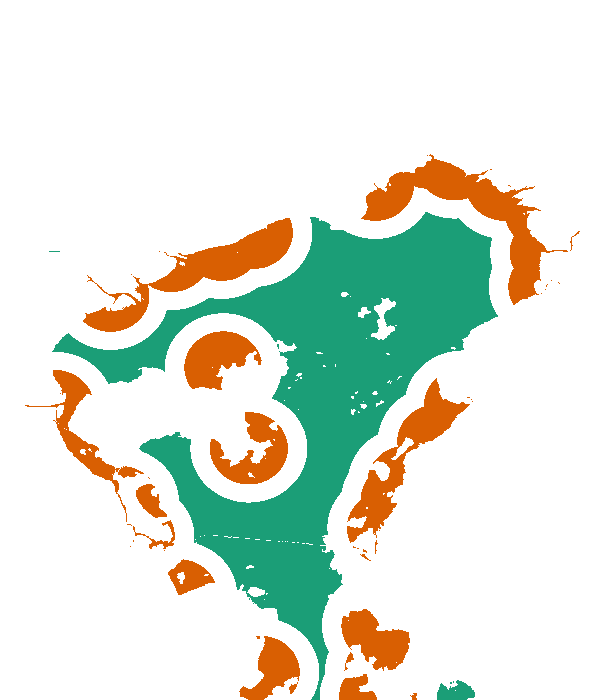

[12:25:56Z] sao_sebastiao: /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/zones_sao_sebastiao.png


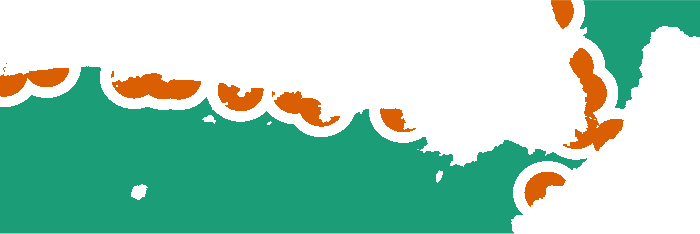

[12:26:00Z] ilha_grande: /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/zones_ilha_grande.png


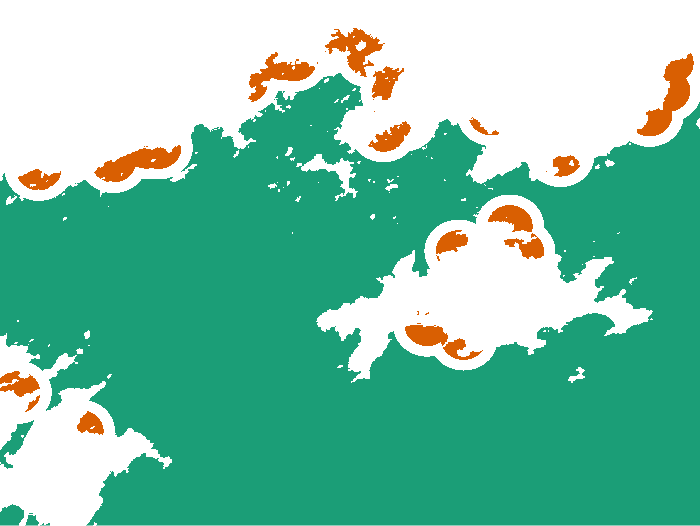

In [ ]:
# MVP4-23 | Zone QA map per site (zone mask only, no reflectance): orange = source, green = far; saved PNG
from IPython.display import Image, display
for s in SITES:
    p = f'{FIG}/zones_{s}.png'
    if not os.path.exists(p):
        url = ZONES[s].visualize(min=1, max=2, palette=['d95f02', '1b9e77']).getThumbURL(
            {'region': ee.Geometry.Rectangle(SITES[s]), 'dimensions': 700, 'format': 'png'})
        r = requests.get(url, timeout=120); r.raise_for_status()
        with open(p + '.tmp', 'wb') as f: f.write(r.content)
        os.replace(p + '.tmp', p)
    hb(f'{s}: {p}'); display(Image(p, width=420))

In [ ]:
# MVP4-24 | Per-date zone statistics (server-side): date-own p99 FDI over site water, exceedance share, mean B4, valid px
S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
CSP = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
RR = dict(scale=Q['scale_m'], crs=Q['crs'], maxPixels=1e10, tileScale=4)
def date_stats(site, d):
    assert_explore(d)
    f = f'{OUT}/stats_{site}_{d}.json'
    if os.path.exists(f): return read_json(f)
    box = ee.Geometry.Rectangle(SITES[site]); d0 = ee.Date(d); d1 = d0.advance(1, 'day')
    s2c, csc = S2.filterBounds(box).filterDate(d0, d1), CSP.filterBounds(box).filterDate(d0, d1)
    if s2c.size().getInfo() == 0 or csc.size().getInfo() == 0:
        res = {'ok': False, 'why': 'no S2 or Cloud Score+ image'}; write_json(f, res); return res
    s2, cs = s2c.mosaic(), csc.select('cs_cdf').mosaic()
    r = lambda b: s2.select(b).divide(1e4)
    fdi = r('B8').subtract(r('B6').add(r('B11').subtract(r('B6')).multiply(Q['fdi_w'] * 10))).rename('fdi')
    near_cloud = cs.lt(Q['cs_thr']).unmask(1).focalMax(Q['cloud_buf_m'], 'circle', 'meters')
    valid = near_cloud.Not().And(WATER).And(s2.select('B8').mask().gt(0))
    thr = ee.Dictionary(fdi.updateMask(valid).reduceRegion(ee.Reducer.percentile([Q['pct']]), box, **RR)).values().get(0).getInfo()
    if thr is None:
        res = {'ok': False, 'why': 'no valid water pixels'}; write_json(f, res); return res
    img = fdi.gt(thr).rename('exc').addBands(r('B4').rename('b4')).addBands(fdi)
    red = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)
    z = lambda k: img.updateMask(valid.And(ZONES[site].eq(k))).reduceRegion(red, box, **RR)
    out = ee.Dictionary({'src': z(1), 'far': z(2)}).getInfo()
    res = {'ok': min(out['src'].get('exc_count', 0), out['far'].get('exc_count', 0)) >= Q['min_zone_px'],
           'thr_p99': thr, 'src': out['src'], 'far': out['far']}
    write_json(f, res); return res
jobs = sorted({(s, p[k]) for s in SITES for p in PAIRS[s] for k in ('event', 'ref')})
pt = ProgressTimer(len(jobs), 'MVP4-24 dates')
for s, d in jobs:
    mem_guard('MVP4-24'); res = date_stats(s, d)
    pt.tick(f"{s} {d} ok={res['ok']}" + ('' if res['ok'] else f" ({res.get('why', 'zone px < min')})"))

[12:26:25Z] MVP4-24 dates 1/48 | 0.4 min elapsed, ~19.8 min left guanabara 2019-01-09 ok=True
[12:26:56Z] MVP4-24 dates 2/48 | 0.9 min elapsed, ~21.6 min left guanabara 2019-01-14 ok=True
[12:27:23Z] MVP4-24 dates 3/48 | 1.4 min elapsed, ~20.8 min left guanabara 2019-01-24 ok=True
[12:27:49Z] MVP4-24 dates 4/48 | 1.8 min elapsed, ~20.0 min left guanabara 2019-02-03 ok=True
[12:28:12Z] MVP4-24 dates 5/48 | 2.2 min elapsed, ~19.0 min left guanabara 2019-02-08 ok=True
[12:28:35Z] MVP4-24 dates 6/48 | 2.6 min elapsed, ~18.1 min left guanabara 2019-05-14 ok=True
[12:29:00Z] MVP4-24 dates 7/48 | 3.0 min elapsed, ~17.6 min left guanabara 2019-05-19 ok=True
[12:29:31Z] MVP4-24 dates 8/48 | 3.5 min elapsed, ~17.6 min left guanabara 2020-02-18 ok=True
[12:29:53Z] MVP4-24 dates 9/48 | 3.9 min elapsed, ~16.9 min left guanabara 2020-03-14 ok=True
[12:30:18Z] MVP4-24 dates 10/48 | 4.3 min elapsed, ~16.4 min left guanabara 2021-01-13 ok=True
[12:30:42Z] MVP4-24 dates 11/48 | 4.7 min elapsed, ~15.8 mi

In [ ]:
# MVP4-25 | Pair contrasts: difference-in-differences of exceedance share (FDI) and of mean B4 (turbidity check)
rows = []
for s in SITES:
    for p in PAIRS[s]:
        E, R = read_json(f"{OUT}/stats_{s}_{p['event']}.json"), read_json(f"{OUT}/stats_{s}_{p['ref']}.json")
        row = {'site': s, 'event': p['event'], 'ref': p['ref'], 'used': bool(E['ok'] and R['ok'])}
        if row['used']:
            d = lambda key, zone: E[zone][key] - R[zone][key]
            row.update({'dS_exc': d('exc_mean', 'src'), 'dF_exc': d('exc_mean', 'far'),
                        'did_exc': d('exc_mean', 'src') - d('exc_mean', 'far'),
                        'did_b4': d('b4_mean', 'src') - d('b4_mean', 'far'),
                        'thr_ev': E['thr_p99'], 'thr_ref': R['thr_p99'],
                        'px_src_min': min(E['src']['exc_count'], R['src']['exc_count']),
                        'px_far_min': min(E['far']['exc_count'], R['far']['exc_count'])})
        rows.append(row)
PC = pd.DataFrame(rows); write_csv(f'{OUT}/pair_contrasts.csv', PC)
print(PC.groupby('site').used.agg(['sum', 'size']).rename(columns={'sum': 'used', 'size': 'pairs'}).to_string())

               used  pairs
site                      
guanabara         7      7
ilha_grande      10     10
sao_sebastiao     9      9


In [ ]:
# MVP4-26 | Per-site exploratory tests: median DiD, exact Wilcoxon and sign test (DiD > 0), bootstrap CI clustered by reference date, B4 check
rng = np.random.default_rng(Q['seed'])
def clustered_ci(df, col, B=Q['boot_B']):
    groups = [g[col].values for _, g in df.groupby('ref')]
    if len(groups) < 2: return [np.nan, np.nan]
    meds = [np.median(np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])) for _ in range(B)]
    return [float(np.percentile(meds, 2.5)), float(np.percentile(meds, 97.5))]
C4 = read_json(f'{IN}/c4_population.json', {})
T = {}
for s in SITES:
    u = PC[(PC.site == s) & PC.used]; x = u.did_exc.values; n = len(x)
    if n == 0: T[s] = {'n': 0}; continue
    nz = x[x != 0]
    T[s] = {'n': n, 'n_ref_dates': u.ref.nunique(), 'pop_2020': C4.get(s, {}).get('pop_2020'),
            'median_did_exc': float(np.median(x)), 'ci95_clustered': clustered_ci(u, 'did_exc'),
            'n_pos': int((x > 0).sum()),
            'wilcoxon_p_1s': float(stats.wilcoxon(nz, alternative='greater').pvalue) if len(nz) >= 2 else np.nan,
            'sign_p_1s': float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue) if len(nz) else np.nan,
            'median_did_b4': float(np.median(u.did_b4)),
            'wilcoxon_b4_p_2s': float(stats.wilcoxon(u.did_b4).pvalue) if n >= 2 else np.nan,
            'spearman_exc_b4': float(stats.spearmanr(u.did_exc, u.did_b4)[0]) if n >= 3 else np.nan}
write_json(f'{OUT}/exploratory_tests.json', T); log_event('exploratory_tests', T)
tab = pd.DataFrame(T).T
for c in ('median_did_exc', 'median_did_b4'): tab[c] = tab[c].astype(float).map(lambda v: f'{v:+.5f}')
print(tab.to_string())
print('p-values are one-sided (DiD > 0) unless marked 2s; exploratory and descriptive only.')

                n n_ref_dates  pop_2020 median_did_exc                                 ci95_clustered n_pos wilcoxon_p_1s sign_p_1s median_did_b4 wilcoxon_b4_p_2s spearman_exc_b4
guanabara       7           6  10900899       +0.01932  [-0.0031862164947306757, 0.03622155668730474]     5      0.109375  0.226562      -0.00084           0.9375        0.678571
sao_sebastiao   9           8    170135       +0.00236   [-0.02240499314604185, 0.015488867297975334]     5      0.455078       0.5      -0.00238         0.300781        0.433333
ilha_grande    10           8    307739       +0.00844   [-0.014576882550994517, 0.06418866240218622]     5      0.161133  0.623047      +0.00148         0.232422        0.733333
p-values are one-sided (DiD > 0) unless marked 2s; exploratory and descriptive only.


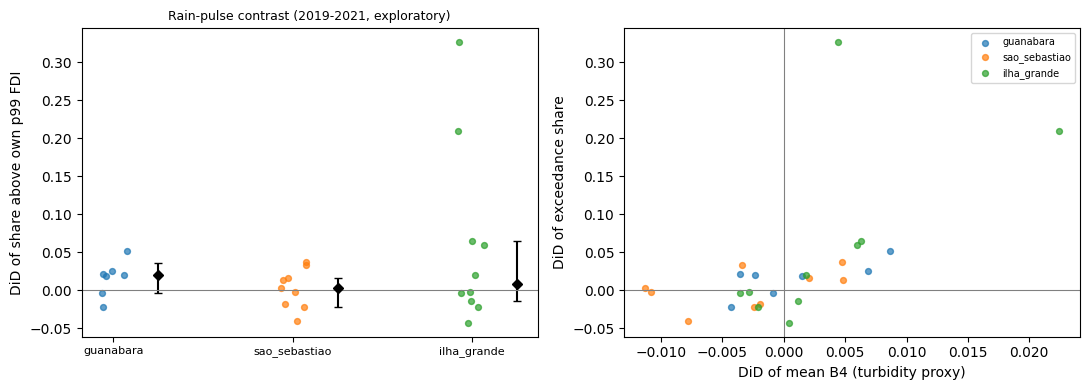

[12:55:17Z] saved /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/mvp4_nb02_did.png


In [ ]:
# MVP4-27 | Figure: DiD of exceedance share per pair and site (median + clustered CI); DiD FDI vs DiD B4 (saved PNG)
used = PC[PC.used]; sites = [s for s in SITES if (used.site == s).any()]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for i, s in enumerate(sites):
    x = used[used.site == s].did_exc.values
    a1.scatter(np.full(len(x), i) + rng.uniform(-0.08, 0.08, len(x)), x, s=18, alpha=0.7, color=f'C{i}')
    lo, hi = T[s]['ci95_clustered']; a1.errorbar(i + 0.25, T[s]['median_did_exc'], yerr=[[T[s]['median_did_exc'] - lo], [hi - T[s]['median_did_exc']]],
                                                 fmt='D', color='k', ms=5, capsize=3)
    a2.scatter(used[used.site == s].did_b4, used[used.site == s].did_exc, s=18, alpha=0.7, color=f'C{i}', label=s)
a1.axhline(0, color='0.5', lw=0.8); a1.set_xticks(range(len(sites))); a1.set_xticklabels(sites, fontsize=8)
a1.set_ylabel('DiD of share above own p99 FDI'); a1.set_title('Rain-pulse contrast (2019-2021, exploratory)', fontsize=9)
a2.axhline(0, color='0.5', lw=0.8); a2.axvline(0, color='0.5', lw=0.8)
a2.set_xlabel('DiD of mean B4 (turbidity proxy)'); a2.set_ylabel('DiD of exceedance share'); a2.legend(fontsize=7)
fig.tight_layout(); p = f'{FIG}/mvp4_nb02_did.png'; fig.savefig(p, dpi=150); plt.show(); plt.close(fig); hb(f'saved {p}')

In [ ]:
# MVP4-28 | Session summary: compact view of the NB02 run log (keys and timestamps only)
for k, v in read_json(LOG, {}).items():
    print(f"{v.get('utc', ''):<26} {k}")

2026-09-24T12:25:44+00:00  env_20260924T122544
2026-09-24T12:25:47+00:00  D-M4-3
2026-09-24T12:25:51+00:00  zones
2026-09-24T12:55:16+00:00  exploratory_tests


In [ ]:
# MVP4-29 | Effect in context: median exceedance share per zone on reference and event dates, and DiD relative to the source baseline
rows = []
for s in SITES:
    u = PC[(PC.site == s) & PC.used]
    g = lambda dates, z: float(np.median([read_json(f'{OUT}/stats_{s}_{d}.json')[z]['exc_mean'] for d in dates]))
    src_ref, src_ev, far_ref, far_ev = g(u.ref, 'src'), g(u.event, 'src'), g(u.ref, 'far'), g(u.event, 'far')
    rows.append({'site': s, 'src_ref': src_ref, 'src_event': src_ev, 'far_ref': far_ref, 'far_event': far_ev,
                 'did_over_src_ref': T[s]['median_did_exc'] / src_ref if src_ref else np.nan})
EC = pd.DataFrame(rows).round(4); write_json(f'{OUT}/effect_context.json', EC.to_dict('records')); print(EC.to_string(index=False))

         site  src_ref  src_event  far_ref  far_event  did_over_src_ref
    guanabara   0.0093     0.0213   0.0082     0.0025            2.0733
sao_sebastiao   0.0608     0.0604   0.0020     0.0028            0.0389
  ilha_grande   0.0410     0.0571   0.0115     0.0080            0.2057


In [ ]:
# MVP4-30 | D-M4-4: far-zone-referenced threshold; primary = source share above far-zone p99 (event - reference); pooled previews
if 'D-M4-4' not in read_json(LOG, {}):
    log_event('D-M4-4', {
        'what': 'Threshold domain changed from all site water to far-zone water (date-own p99). Primary pair contrast = '
                'source-zone exceedance share, event minus reference. Previous stats kept (stats_*); new ones in statsF_*.',
        'why': 'Site-wide percentile makes zone shares compositional (~1% overall), so a source rise forces a far drop and the '
               'DiD double-counts (MVP4-29: Guanabara far 0.82% -> 0.25%). A far-zone threshold removes the coupling.',
        'data_seen': 'Exploratory 2019-2021 NB02 results (MVP4-26, MVP4-29) only. No 2022+ reflectance.'})
def date_stats_far(site, d):
    assert_explore(d)
    f = f'{OUT}/statsF_{site}_{d}.json'
    if os.path.exists(f): return read_json(f)
    box = ee.Geometry.Rectangle(SITES[site]); d0 = ee.Date(d); d1 = d0.advance(1, 'day')
    s2c, csc = S2.filterBounds(box).filterDate(d0, d1), CSP.filterBounds(box).filterDate(d0, d1)
    if s2c.size().getInfo() == 0 or csc.size().getInfo() == 0:
        res = {'ok': False, 'why': 'no S2 or Cloud Score+ image'}; write_json(f, res); return res
    s2, cs = s2c.mosaic(), csc.select('cs_cdf').mosaic()
    r = lambda b: s2.select(b).divide(1e4)
    fdi = r('B8').subtract(r('B6').add(r('B11').subtract(r('B6')).multiply(Q['fdi_w'] * 10))).rename('fdi')
    valid = (cs.lt(Q['cs_thr']).unmask(1).focalMax(Q['cloud_buf_m'], 'circle', 'meters').Not()
             .And(WATER).And(s2.select('B8').mask().gt(0)))
    thr = ee.Dictionary(fdi.updateMask(valid.And(ZONES[site].eq(2)))
                        .reduceRegion(ee.Reducer.percentile([Q['pct']]), box, **RR)).values().get(0).getInfo()
    if thr is None:
        res = {'ok': False, 'why': 'no valid far-zone pixels'}; write_json(f, res); return res
    img = fdi.gt(thr).rename('exc').addBands(r('B4').rename('b4'))
    red = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)
    z = lambda k: img.updateMask(valid.And(ZONES[site].eq(k))).reduceRegion(red, box, **RR)
    out = ee.Dictionary({'src': z(1), 'far': z(2)}).getInfo()
    res = {'ok': min(out['src'].get('exc_count', 0), out['far'].get('exc_count', 0)) >= Q['min_zone_px'],
           'thr_far_p99': thr, **out}
    write_json(f, res); return res
pt = ProgressTimer(len(jobs), 'MVP4-30 dates')
for s, d in jobs:
    mem_guard('MVP4-30'); res = date_stats_far(s, d); pt.tick(f"{s} {d} ok={res['ok']}")
rows = []
for s in SITES:
    for p in PAIRS[s]:
        E, R = (read_json(f"{OUT}/statsF_{s}_{p[k]}.json") for k in ('event', 'ref'))
        ok = bool(E['ok'] and R['ok']); row = {'site': s, 'event': p['event'], 'ref': p['ref'], 'used': ok}
        if ok:
            row.update({'dS': E['src']['exc_mean'] - R['src']['exc_mean'], 'src_ref': R['src']['exc_mean'],
                        'far_ref': R['far']['exc_mean'], 'far_ev': E['far']['exc_mean'],
                        'did_b4': (E['src']['b4_mean'] - R['src']['b4_mean']) - (E['far']['b4_mean'] - R['far']['b4_mean'])})
        rows.append(row)
PF = pd.DataFrame(rows); write_csv(f'{OUT}/pair_contrasts_far.csv', PF); U = PF[PF.used].reset_index(drop=True)
TF = {}
for s in SITES:
    u = U[U.site == s]; x = u.dS.values; nz = x[x != 0]
    TF[s] = {'n': len(x), 'src_ref_med': float(u.src_ref.median()), 'far_ref_med': float(u.far_ref.median()),
             'median_dS': float(np.median(x)), 'ci95_clustered': [round(v, 4) for v in clustered_ci(u, 'dS')],
             'n_pos': int((x > 0).sum()),
             'wilcoxon_p_1s': float(stats.wilcoxon(nz, alternative='greater').pvalue) if len(nz) >= 2 else np.nan,
             'sign_p_1s': float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue) if len(nz) else np.nan,
             'spearman_dS_b4': float(stats.spearmanr(u.dS, u.did_b4)[0]) if len(x) >= 3 else np.nan}
site_idx = [np.where(U.site.values == s)[0] for s in SITES if (U.site == s).any()]
stat = lambda v: np.mean([v[i].mean() for i in site_idx])                      # equal weight per site
obs = stat(U.dS.values); flips = rng.choice([-1.0, 1.0], size=(20000, len(U)))
null = np.array([stat(U.dS.values * f) for f in flips])
X, y = np.column_stack([np.ones(len(U)), U.did_b4.values]), U.dS.values
keys = (U.site + '|' + U.ref).values; groups = [np.where(keys == k)[0] for k in np.unique(keys)]
a_hat = np.linalg.lstsq(X, y, rcond=None)[0][0]
a_boot = [np.linalg.lstsq(X[ii], y[ii], rcond=None)[0][0] for ii in
          (np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]) for _ in range(Q['boot_B']))]
POOL = {'n': len(U), 'site_mean_dS': float(obs), 'signflip_p_1s': float((np.sum(null >= obs) + 1) / (len(null) + 1)),
        'turbidity_adj_intercept': float(a_hat), 'intercept_ci95_clustered': [float(np.percentile(a_boot, q)) for q in (2.5, 97.5)]}
write_json(f'{OUT}/exploratory_tests_far.json', {'per_site': TF, 'pooled': POOL}); log_event('exploratory_tests_far', {'pooled': POOL})
print(pd.DataFrame(TF).T.to_string()); print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in POOL.items()})
print('One-sided p (dS > 0); exploratory, descriptive only.')

[15:41:19Z] MVP4-30 dates 1/48 | 0.6 min elapsed, ~26.7 min left guanabara 2019-01-09 ok=True
[15:41:44Z] MVP4-30 dates 2/48 | 1.0 min elapsed, ~22.8 min left guanabara 2019-01-14 ok=True
[15:42:14Z] MVP4-30 dates 3/48 | 1.5 min elapsed, ~22.4 min left guanabara 2019-01-24 ok=True
[15:42:47Z] MVP4-30 dates 4/48 | 2.0 min elapsed, ~22.5 min left guanabara 2019-02-03 ok=True
[15:43:15Z] MVP4-30 dates 5/48 | 2.5 min elapsed, ~21.6 min left guanabara 2019-02-08 ok=True
[15:43:53Z] MVP4-30 dates 6/48 | 3.1 min elapsed, ~22.0 min left guanabara 2019-05-14 ok=True
[15:44:21Z] MVP4-30 dates 7/48 | 3.6 min elapsed, ~21.1 min left guanabara 2019-05-19 ok=True
[15:44:51Z] MVP4-30 dates 8/48 | 4.1 min elapsed, ~20.6 min left guanabara 2020-02-18 ok=True
[15:45:21Z] MVP4-30 dates 9/48 | 4.6 min elapsed, ~19.9 min left guanabara 2020-03-14 ok=True
[15:45:49Z] MVP4-30 dates 10/48 | 5.1 min elapsed, ~19.3 min left guanabara 2021-01-13 ok=True
[15:46:18Z] MVP4-30 dates 11/48 | 5.6 min elapsed, ~18.7 mi

In [12]:
# MVP4-31 | D-M4-5: full span 2019-2025 (all p90 pairs), MVP4-30 metric unchanged; 2026 refused (future holdout); fixed analysis set
if 'D-M4-5' not in read_json(LOG, {}):
    log_event('D-M4-5', {
        'what': 'Analysis extended to all p90 rain-pulse pairs 2019-2025 with the MVP4-30 metric and parameters unchanged. '
                'The 2023-2025 holdout is used; results are exploratory. 2026 is refused by the guard (future holdout).',
        'why': 'Team decision: estimate the best achievable with all available pairs.',
        'data_seen': 'Exploratory 2019-2021 results (MVP4-26, MVP4-29, MVP4-30).',
        'analysis_fixed_before_run': 'primary = Guanabara dS > 0 (Wilcoxon 1-sided); secondary = per-site tests, pooled sign-flip, '
                                     'turbidity-adjusted intercept (Guanabara, pooled), per-period medians. No further variants.'})
Q['explore_last_year'] = 2025                                    # guard now refuses 2026+
period_of = lambda y: 'explore' if y <= 2021 else ('buffer' if y == 2022 else 'confirm')
PAIRS_ALL = {s: [p for p in P90[s]['pairs'] if max(pd.Timestamp(p['event']).year, pd.Timestamp(p['ref']).year) <= 2025] for s in SITES}
jobs_all = sorted({(s, p[k]) for s in SITES for p in PAIRS_ALL[s] for k in ('event', 'ref')})
todo = [j for j in jobs_all if not os.path.exists(f'{OUT}/statsF_{j[0]}_{j[1]}.json')]
hb(f"pairs {({s: len(v) for s, v in PAIRS_ALL.items()})} | dates {len(jobs_all)}, new {len(todo)}")
pt = ProgressTimer(max(len(todo), 1), 'MVP4-31 dates')
for s, d in todo:
    mem_guard('MVP4-31'); res = date_stats_far(s, d); pt.tick(f"{s} {d} ok={res['ok']}")
rows = []
for s in SITES:
    for p in PAIRS_ALL[s]:
        E, R = (read_json(f"{OUT}/statsF_{s}_{p[k]}.json") for k in ('event', 'ref'))
        row = {'site': s, 'event': p['event'], 'ref': p['ref'], 'period': period_of(pd.Timestamp(p['event']).year),
               'used': bool(E['ok'] and R['ok'])}
        if row['used']:
            row.update({'dS': E['src']['exc_mean'] - R['src']['exc_mean'], 'src_ref': R['src']['exc_mean'],
                        'did_b4': (E['src']['b4_mean'] - R['src']['b4_mean']) - (E['far']['b4_mean'] - R['far']['b4_mean'])})
        rows.append(row)
PA = pd.DataFrame(rows); write_csv(f'{OUT}/pair_contrasts_full.csv', PA); UA = PA[PA.used].reset_index(drop=True)
def site_tests(u):
    x = u.dS.values; nz = x[x != 0]
    return {'n': len(x), 'n_ref': u.ref.nunique(), 'src_ref_med': round(float(u.src_ref.median()), 4),
            'median_dS': round(float(np.median(x)), 4), 'ci95_clustered': [round(v, 4) for v in clustered_ci(u, 'dS')],
            'n_pos': int((x > 0).sum()),
            'wilcoxon_p_1s': round(float(stats.wilcoxon(nz, alternative='greater').pvalue), 4) if len(nz) >= 2 else np.nan,
            'sign_p_1s': round(float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue), 4) if len(nz) else np.nan,
            'spearman_dS_b4': round(float(stats.spearmanr(u.dS, u.did_b4)[0]), 3) if len(x) >= 3 else np.nan}
def adj_intercept(u):
    X, y = np.column_stack([np.ones(len(u)), u.did_b4.values]), u.dS.values
    keys = (u.site + '|' + u.ref).values; g = [np.where(keys == k)[0] for k in np.unique(keys)]
    bs = [np.linalg.lstsq(X[ii], y[ii], rcond=None)[0][0] for ii in
          (np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))]) for _ in range(Q['boot_B']))]
    return {'intercept': round(float(np.linalg.lstsq(X, y, rcond=None)[0][0]), 5),
            'ci95_clustered': [round(float(np.percentile(bs, q)), 5) for q in (2.5, 97.5)]}
TA = {s: site_tests(UA[UA.site == s]) for s in SITES if (UA.site == s).any()}
site_idx = [np.where(UA.site.values == s)[0] for s in TA]
stat = lambda v: np.mean([v[i].mean() for i in site_idx])
obs = stat(UA.dS.values); null = np.array([stat(UA.dS.values * f) for f in rng.choice([-1.0, 1.0], size=(20000, len(UA)))])
POOL = {'n': len(UA), 'site_mean_dS': round(float(obs), 5), 'signflip_p_1s': round(float((np.sum(null >= obs) + 1) / 20001), 4),
        'adj_pooled': adj_intercept(UA), 'adj_guanabara': adj_intercept(UA[UA.site == 'guanabara'])}
PER = UA.groupby(['site', 'period']).dS.agg(['size', 'median']).round(4)
write_json(f'{OUT}/results_full_span.json', {'per_site': TA, 'pooled': POOL, 'per_period': PER.reset_index().to_dict('records')})
log_event('results_full_span', {'pooled': POOL})
print(pd.DataFrame(TA).T.to_string()); print(POOL); print(PER.unstack('period').to_string())
print('One-sided p (dS > 0); exploratory, descriptive only. Primary = Guanabara wilcoxon_p_1s.')

[16:26:06Z] pairs {'guanabara': 23, 'sao_sebastiao': 30, 'ilha_grande': 24} | dates 134, new 86
[16:26:25Z] MVP4-31 dates 1/86 | 0.3 min elapsed, ~26.8 min left guanabara 2022-02-22 ok=True
[16:26:52Z] MVP4-31 dates 2/86 | 0.8 min elapsed, ~32.4 min left guanabara 2022-03-04 ok=True
[16:27:14Z] MVP4-31 dates 3/86 | 1.1 min elapsed, ~31.4 min left guanabara 2022-04-13 ok=True
[16:27:34Z] MVP4-31 dates 4/86 | 1.5 min elapsed, ~29.9 min left guanabara 2022-04-23 ok=True
[16:28:02Z] MVP4-31 dates 5/86 | 1.9 min elapsed, ~31.2 min left guanabara 2022-09-10 ok=True
[16:28:30Z] MVP4-31 dates 6/86 | 2.4 min elapsed, ~31.9 min left guanabara 2022-09-25 ok=True
[16:28:59Z] MVP4-31 dates 7/86 | 2.9 min elapsed, ~32.6 min left guanabara 2023-02-27 ok=True
[16:29:21Z] MVP4-31 dates 8/86 | 3.3 min elapsed, ~31.7 min left guanabara 2023-03-24 ok=True
[16:29:38Z] MVP4-31 dates 9/86 | 3.5 min elapsed, ~30.2 min left guanabara 2023-04-13 ok=True
[16:30:08Z] MVP4-31 dates 10/86 | 4.0 min elapsed, ~30.7 m

[16:37:34Z] MVP4-31 dates 26/86 | 11.5 min elapsed, ~26.5 min left guanabara 2025-04-27 ok=True
[16:37:59Z] MVP4-31 dates 27/86 | 11.9 min elapsed, ~26.0 min left guanabara 2025-05-07 ok=True
[16:38:52Z] MVP4-31 dates 28/86 | 12.8 min elapsed, ~26.4 min left ilha_grande 2022-02-22 ok=True
[16:39:46Z] MVP4-31 dates 29/86 | 13.7 min elapsed, ~26.9 min left ilha_grande 2022-03-09 ok=True
[16:40:26Z] MVP4-31 dates 30/86 | 14.3 min elapsed, ~26.7 min left ilha_grande 2022-03-24 ok=True
[16:41:15Z] MVP4-31 dates 31/86 | 15.1 min elapsed, ~26.9 min left ilha_grande 2022-04-08 ok=True
[16:42:10Z] MVP4-31 dates 32/86 | 16.1 min elapsed, ~27.1 min left ilha_grande 2022-04-13 ok=True
[16:42:59Z] MVP4-31 dates 33/86 | 16.9 min elapsed, ~27.1 min left ilha_grande 2022-04-23 ok=True
[16:43:55Z] MVP4-31 dates 34/86 | 17.8 min elapsed, ~27.2 min left ilha_grande 2022-12-09 ok=True
[16:44:47Z] MVP4-31 dates 35/86 | 18.7 min elapsed, ~27.2 min left ilha_grande 2022-12-24 ok=True
[16:45:37Z] MVP4-31 date

In [13]:
# MVP4-32 | D-M4-7 pre-declared ghost check, part 1: sun-glint angle (S2 scene metadata) vs Guanabara pair contrasts
if 'D-M4-7' not in read_json(LOG, {}):
    log_event('D-M4-7', {
        'what': 'Ghost check on the Guanabara result: (1) glint angle from S2 metadata vs dS; (2) true-colour quicklooks '
                'with p99 exceedances for the 5 largest-dS pairs.',
        'rules': {'glint_suspect': 'Spearman(dS, event glint) <= -0.5 OR Spearman(dS, event-minus-ref glint) <= -0.5 '
                                   'OR median event glint < 25 deg',
                  'visual_suspect': 'majority of the 5 event images show exceedances mainly along shorelines, cloud/haze '
                                    'edges, or as isolated boat-like dots',
                  'otherwise': 'no ghost signal found by these checks (other ghosts not excluded)'},
        'data_seen': 'Full-span results (MVP4-31). No geometry values or quicklooks yet.'})
ANG = ('MEAN_SOLAR_ZENITH_ANGLE', 'MEAN_SOLAR_AZIMUTH_ANGLE', 'MEAN_INCIDENCE_ZENITH_ANGLE_B8', 'MEAN_INCIDENCE_AZIMUTH_ANGLE_B8')
def geometry(d, site='guanabara'):
    f = f'{OUT}/geom_{site}_{d}.json'
    if os.path.exists(f): return read_json(f)
    c = S2.filterBounds(ee.Geometry.Rectangle(SITES[site])).filterDate(ee.Date(d), ee.Date(d).advance(1, 'day'))
    g = ee.Dictionary({k: c.aggregate_mean(k) for k in ANG}).getInfo(); write_json(f, g); return g
def glint_deg(g):   # angle between specular sun direction and view direction (S2 azimuth convention: to verify)
    ts, tv = np.radians(g[ANG[0]]), np.radians(g[ANG[2]]); dphi = np.radians(g[ANG[1]] - g[ANG[3]])
    return float(np.degrees(np.arccos(np.clip(np.cos(ts) * np.cos(tv) - np.sin(ts) * np.sin(tv) * np.cos(dphi), -1, 1))))
G = UA[UA.site == 'guanabara'].copy().reset_index(drop=True)
pt = ProgressTimer(len(G), 'MVP4-32 geometry'); ge, gr = [], []
for _, r in G.iterrows():
    ge.append(glint_deg(geometry(r.event))); gr.append(glint_deg(geometry(r.ref))); pt.tick()
G['glint_ev'], G['glint_ref'] = ge, gr; G['d_glint'] = G.glint_ev - G.glint_ref
rho1, rho2, med = stats.spearmanr(G.dS, G.glint_ev)[0], stats.spearmanr(G.dS, G.d_glint)[0], float(G.glint_ev.median())
GL = {'n': len(G), 'spearman_dS_glint_event': round(float(rho1), 3), 'spearman_dS_dglint': round(float(rho2), 3),
      'median_glint_event_deg': round(med, 1), 'min_glint_event_deg': round(float(G.glint_ev.min()), 1),
      'glint_suspect': bool(rho1 <= -0.5 or rho2 <= -0.5 or med < 25)}
write_csv(f'{OUT}/guanabara_pairs_glint.csv', G); log_event('ghost_glint', GL); print(GL)

[17:19:30Z] MVP4-32 geometry 1/23 | 0.0 min elapsed, ~0.7 min left 
[17:19:32Z] MVP4-32 geometry 2/23 | 0.1 min elapsed, ~0.6 min left 
[17:19:33Z] MVP4-32 geometry 3/23 | 0.1 min elapsed, ~0.5 min left 
[17:19:34Z] MVP4-32 geometry 4/23 | 0.1 min elapsed, ~0.5 min left 
[17:19:37Z] MVP4-32 geometry 5/23 | 0.1 min elapsed, ~0.5 min left 
[17:19:38Z] MVP4-32 geometry 6/23 | 0.2 min elapsed, ~0.5 min left 
[17:19:41Z] MVP4-32 geometry 7/23 | 0.2 min elapsed, ~0.5 min left 
[17:19:43Z] MVP4-32 geometry 8/23 | 0.2 min elapsed, ~0.5 min left 
[17:19:46Z] MVP4-32 geometry 9/23 | 0.3 min elapsed, ~0.5 min left 
[17:19:48Z] MVP4-32 geometry 10/23 | 0.3 min elapsed, ~0.4 min left 
[17:19:51Z] MVP4-32 geometry 11/23 | 0.4 min elapsed, ~0.4 min left 
[17:19:52Z] MVP4-32 geometry 12/23 | 0.4 min elapsed, ~0.4 min left 
[17:19:54Z] MVP4-32 geometry 13/23 | 0.4 min elapsed, ~0.3 min left 
[17:19:56Z] MVP4-32 geometry 14/23 | 0.5 min elapsed, ~0.3 min left 
[17:19:57Z] MVP4-32 geometry 15/23 | 0.5 mi

In [14]:
# MVP4-33 | Ghost check, part 2: true-colour quicklooks (event | reference), p99 exceedances red (dilated for visibility), source-zone edge yellow
from PIL import Image as PILImage
def quicklook(site, d):
    p = f'{FIG}/ql_{site}_{d}.png'
    if os.path.exists(p): return p
    st, box = read_json(f'{OUT}/statsF_{site}_{d}.json'), ee.Geometry.Rectangle(SITES[site])
    d0, d1 = ee.Date(d), ee.Date(d).advance(1, 'day')
    s2 = S2.filterBounds(box).filterDate(d0, d1).mosaic()
    cs = CSP.filterBounds(box).filterDate(d0, d1).select('cs_cdf').mosaic()
    r = lambda b: s2.select(b).divide(1e4)
    fdi = r('B8').subtract(r('B6').add(r('B11').subtract(r('B6')).multiply(Q['fdi_w'] * 10)))
    valid = cs.lt(Q['cs_thr']).unmask(1).focalMax(Q['cloud_buf_m'], 'circle', 'meters').Not().And(WATER)
    exc = (fdi.gt(st['thr_far_p99']).And(valid).And(ZONES[site].mask()).selfMask()
           .focalMax(30, 'circle', 'meters').visualize(palette=['ff0000']))
    src = ZONES[site].eq(1).unmask(0)
    edge = src.focalMax(40, 'circle', 'meters').neq(src.focalMin(40, 'circle', 'meters')).selfMask().visualize(palette=['ffff00'])
    rgb = s2.select(['B4', 'B3', 'B2']).visualize(min=0, max=2000, gamma=1.3)
    url = ee.ImageCollection([rgb, edge, exc]).mosaic().getThumbURL({'region': box, 'dimensions': 1200, 'format': 'png'})
    rq = requests.get(url, timeout=180); rq.raise_for_status()
    with open(p + '.tmp', 'wb') as f: f.write(rq.content)
    os.replace(p + '.tmp', p); return p
TOP = G.nlargest(5, 'dS').reset_index(drop=True)
fig, axes = plt.subplots(len(TOP), 2, figsize=(10, 4.2 * len(TOP)))
pt = ProgressTimer(len(TOP), 'MVP4-33 quicklooks')
for i, r in TOP.iterrows():
    for j, (d, lab) in enumerate(((r.event, 'EVENT'), (r.ref, 'REFERENCE'))):
        axes[i, j].imshow(PILImage.open(quicklook('guanabara', d))); axes[i, j].axis('off')
        axes[i, j].set_title(f'{lab} {d}' + (f'  (dS = {r.dS:+.3f}, glint {r.glint_ev:.0f} deg)' if j == 0 else ''), fontsize=8)
    pt.tick(r.event)
fig.tight_layout(); p = f'{FIG}/mvp4_guanabara_quicklooks_top5.png'; fig.savefig(p, dpi=130); plt.show(); plt.close(fig)
hb(f'saved {p}')
print('Visual checklist per EVENT image (team fills in): red mainly (a) at outlets as patches/lines, (b) along shorelines, '
      '(c) at cloud/haze edges, (d) isolated boat-like dots, (e) broad plume-like areas.')

Output hidden; open in https://colab.research.google.com to view.

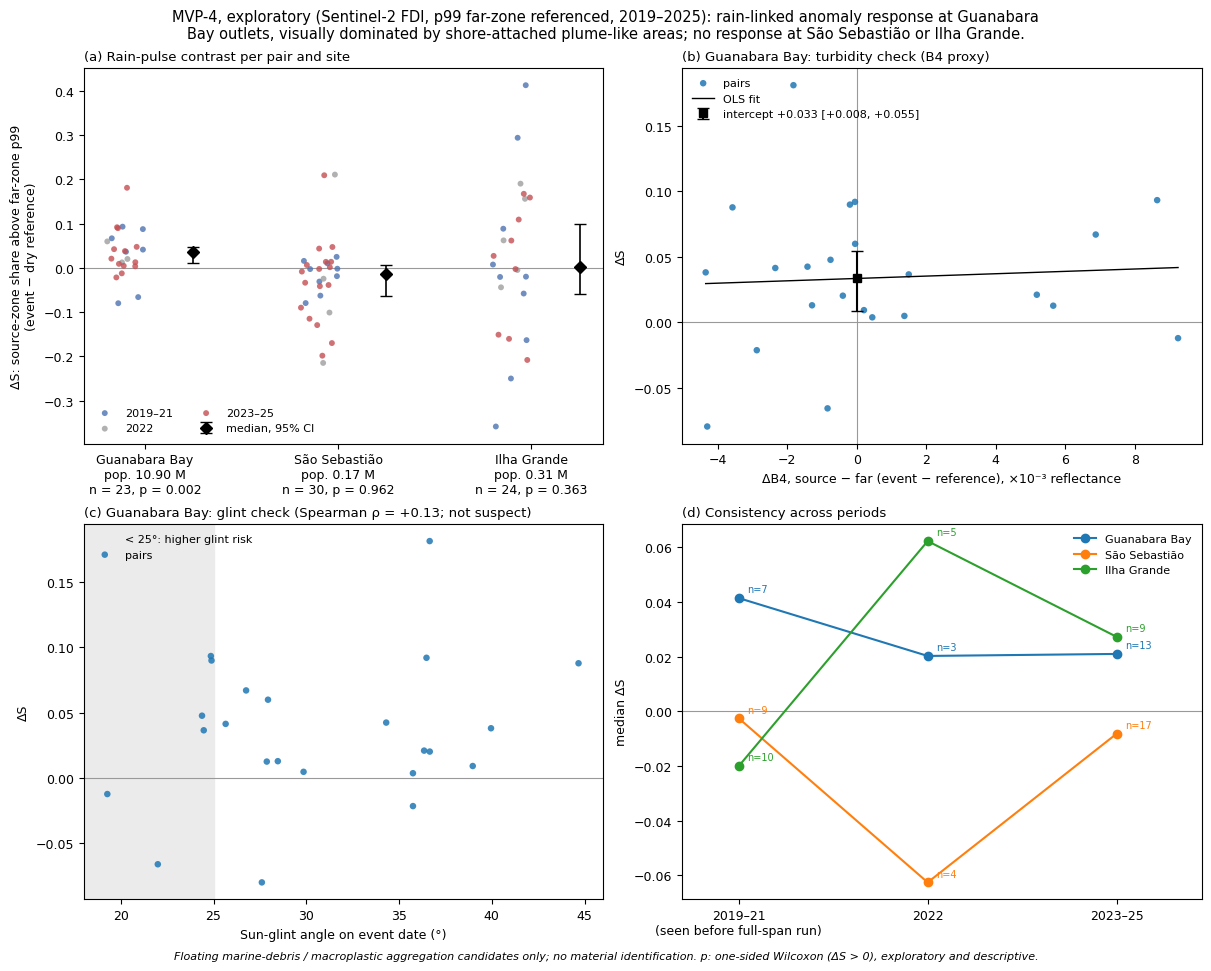

[17:35:07Z] saved /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/mvp4_summary_figure.png / .pdf


In [18]:
# MVP4-34 | Summary figure of MVP-4 (clean version): per-site contrasts, turbidity check, glint check, period consistency
import textwrap
NAME = {'guanabara': 'Guanabara Bay', 'sao_sebastiao': 'São Sebastião', 'ilha_grande': 'Ilha Grande'}
SCOL = {'guanabara': '#1f77b4', 'sao_sebastiao': '#ff7f0e', 'ilha_grande': '#2ca02c'}
PER = [('explore', '2019–21', '#4c72b0'), ('buffer', '2022', '#9e9e9e'), ('confirm', '2023–25', '#c44e52')]
POPS = read_json(f'{IN}/c4_population.json'); jit = np.random.default_rng(1)
sites = [s for s in SITES if s in TA]
plt.rcParams.update({'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9, 'legend.fontsize': 8})
fig, ax = plt.subplots(2, 2, figsize=(12, 9.4), constrained_layout=True); a, b, c, d = ax.ravel()

# (a) per-pair contrasts by site, coloured by period; median and clustered 95% CI
for i, s in enumerate(sites):
    u = UA[UA.site == s]
    for k, lab, col in PER:
        v = u[u.period == k].dS.values
        a.scatter(i - 0.1 + jit.uniform(-0.1, 0.1, len(v)), v, s=18, alpha=0.8, color=col, edgecolor='none',
                  label=lab if i == 0 else None)
    m, (lo, hi) = TA[s]['median_dS'], TA[s]['ci95_clustered']
    a.errorbar(i + 0.25, m, yerr=[[m - lo], [hi - m]], fmt='D', color='k', ms=6, capsize=4, lw=1.2,
               label='median, 95% CI' if i == 0 else None)
a.axhline(0, color='0.6', lw=0.8, zorder=0); a.set_xticks(range(len(sites)))
a.set_xticklabels([f"{NAME[s]}\npop. {POPS[s]['pop_2020'] / 1e6:.2f} M\nn = {TA[s]['n']}, p = {TA[s]['wilcoxon_p_1s']:.3f}"
                   for s in sites])
a.set_ylabel('ΔS: source-zone share above far-zone p99\n(event − dry reference)')
a.set_title('(a) Rain-pulse contrast per pair and site', loc='left'); a.legend(loc='lower left', ncol=2, frameon=False)

# (b) Guanabara: turbidity check, OLS line and turbidity-adjusted intercept (clustered 95% CI)
gc = SCOL['guanabara']; xs = np.linspace(G.did_b4.min(), G.did_b4.max(), 50); cf = np.polyfit(G.did_b4, G.dS, 1)
b.scatter(G.did_b4 * 1e3, G.dS, s=22, color=gc, alpha=0.85, edgecolor='none', label='pairs')
b.plot(xs * 1e3, np.polyval(cf, xs), color='k', lw=1, label='OLS fit')
ai = POOL['adj_guanabara']; lo, hi = ai['ci95_clustered']
b.errorbar(0, ai['intercept'], yerr=[[ai['intercept'] - lo], [hi - ai['intercept']]], fmt='s', color='k', ms=6, capsize=4,
           zorder=5, label=f"intercept {ai['intercept']:+.3f} [{lo:+.3f}, {hi:+.3f}]")
b.axhline(0, color='0.6', lw=0.8, zorder=0); b.axvline(0, color='0.6', lw=0.8, zorder=0)
b.set_xlabel('ΔB4, source − far (event − reference), ×10⁻³ reflectance'); b.set_ylabel('ΔS')
b.set_title('(b) Guanabara Bay: turbidity check (B4 proxy)', loc='left'); b.legend(loc='upper left', frameon=False)

# (c) Guanabara: glint check against the event-date sun-glint angle
x0 = min(18.0, float(G.glint_ev.min()) - 1)
c.axvspan(x0, 25, color='0.92', zorder=0, label='< 25°: higher glint risk')
c.scatter(G.glint_ev, G.dS, s=22, color=gc, alpha=0.85, edgecolor='none', label='pairs')
c.axhline(0, color='0.6', lw=0.8, zorder=0); c.set_xlim(left=x0)
c.set_xlabel('Sun-glint angle on event date (°)'); c.set_ylabel('ΔS')
c.set_title(f"(c) Guanabara Bay: glint check (Spearman ρ = {GL['spearman_dS_glint_event']:+.2f}; "
            f"{'suspect' if GL['glint_suspect'] else 'not suspect'})", loc='left')
c.legend(loc='upper left', frameon=False)

# (d) consistency of the median contrast across periods
for s in sites:
    q = UA[UA.site == s].groupby('period').dS.agg(['median', 'size']).reindex([k for k, _, _ in PER])
    d.plot(range(3), q['median'], marker='o', color=SCOL[s], lw=1.5, label=NAME[s])
    for k, (mv, nv) in enumerate(zip(q['median'], q['size'])):
        if pd.notna(mv):
            d.annotate(f'n={int(nv)}', (k, mv), textcoords='offset points', xytext=(6, 4), fontsize=7, color=SCOL[s])
d.axhline(0, color='0.6', lw=0.8, zorder=0); d.set_xticks(range(3)); d.set_xlim(-0.3, 2.45)
d.set_xticklabels(['2019–21\n(seen before full-span run)', '2022', '2023–25'])
d.set_ylabel('median ΔS'); d.set_title('(d) Consistency across periods', loc='left'); d.legend(loc='best', frameon=False)

fig.suptitle('\n'.join(textwrap.wrap(
    'MVP-4, exploratory (Sentinel-2 FDI, p99 far-zone referenced, 2019–2025): rain-linked anomaly response at Guanabara Bay '
    'outlets, visually dominated by shore-attached plume-like areas; no response at São Sebastião or Ilha Grande.', 115)),
    fontsize=10.5)
fig.text(0.5, -0.015, 'Floating marine-debris / macroplastic aggregation candidates only; no material identification. '
         'p: one-sided Wilcoxon (ΔS > 0), exploratory and descriptive.', ha='center', fontsize=8, style='italic')
p = f'{FIG}/mvp4_summary_figure'
for ext in ('png', 'pdf'):
    fig.savefig(f'{p}.{ext}', dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
log_event('summary_figure', {'paths': [f'{p}.png', f'{p}.pdf']}); hb(f'saved {p}.png / .pdf')

In [16]:
# MVP4-35 | Record D-M4-7 outcome (glint + visual) and the final MVP-4 reading
log_event('ghost_check_outcome', {
    'glint': GL,
    'visual_reading': {'2023-04-13': 'b+e', '2021-01-13': 'b+e (c possible)', '2025-04-12': 'b+e',
                       '2024-01-18': 'e', '2019-05-19': 'b+e'},
    'visual_suspect': True,
    'reading': 'Guanabara rain-linked FDI response dominated by broad shore-attached plume-like anomalies at the northern '
               'river mouths; consistent with runoff plumes (sediment/organic/phytoplankton); not discrete floating aggregations. '
               'FDI anomaly share needs a discrimination step before use as a debris indicator.',
    'reader': 'team (to confirm)'})
hb('D-M4-7 outcome logged')

[17:32:09Z] D-M4-7 outcome logged


[17:57:16Z] manuscript_numbers.json saved


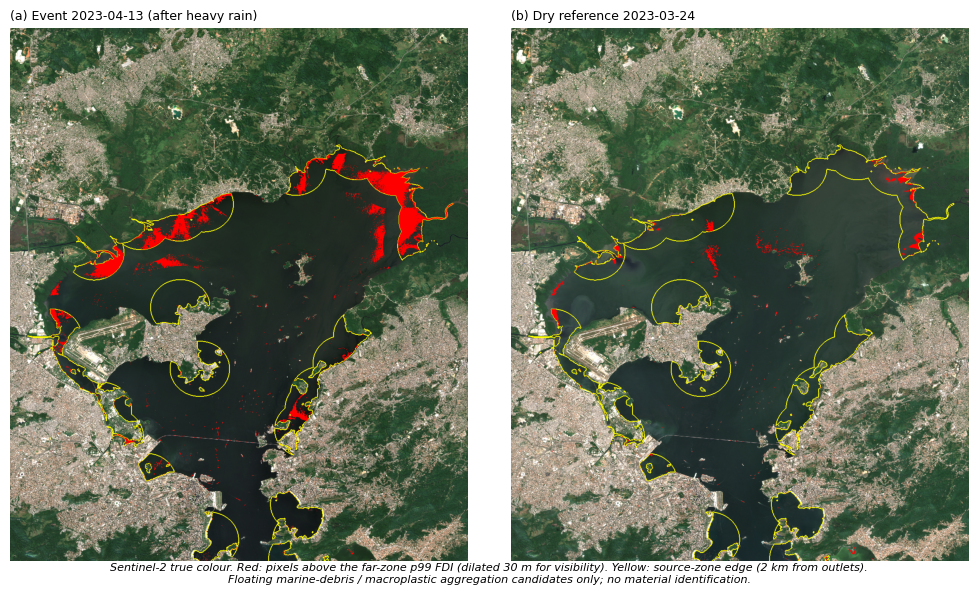

[17:57:23Z] saved /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_nb02/figures/mvp4_example_event_guanabara.png / .pdf
[17:57:26Z] manifest: 323 files hashed; environment frozen. Session can close.


In [24]:
# MVP4-36 | Close-out: manuscript numbers file, example-event figure, SHA-256 manifest of MVP-4 outputs, environment freeze
import subprocess, glob
from PIL import Image as PILImage
L1, L2 = read_json(f'{IN}/mvp4_log.json', {}), read_json(LOG, {})
NUM = {'feasibility_p90': {s: {k: v for k, v in d.items() if k != 'pairs'}
                           for s, d in read_json(f'{IN}/mvp4_feasibility_summary_p90.json').items()},
       'c4_population': read_json(f'{IN}/c4_population.json'),
       'catchments': {s: L1.get(f'catchment_{s}') for s in SITES},
       'outlets_merged': L1.get('outlets_merged'), 'zones': L2.get('zones'),
       'exploratory_2019_21': read_json(f'{OUT}/exploratory_tests_far.json'),
       'full_span_2019_25': read_json(f'{OUT}/results_full_span.json'),
       'ghost_glint': L2.get('ghost_glint'), 'ghost_outcome': L2.get('ghost_check_outcome'),
       'deviations': {k: v for k, v in {**L1, **L2}.items() if k.startswith('D-M4')}}
write_json(f'{OUT}/manuscript_numbers.json', NUM); hb('manuscript_numbers.json saved')

ev, rf = '2023-04-13', '2023-03-24'                                    # strongest Guanabara pair (MVP4-33)
fig, axs = plt.subplots(1, 2, figsize=(10, 5.6), constrained_layout=True)
for axx, dte, lab in ((axs[0], ev, f'(a) Event {ev} (after heavy rain)'), (axs[1], rf, f'(b) Dry reference {rf}')):
    axx.imshow(PILImage.open(quicklook('guanabara', dte))); axx.axis('off'); axx.set_title(lab, loc='left', fontsize=9)
fig.text(0.5, -0.03, 'Sentinel-2 true colour. Red: pixels above the far-zone p99 FDI (dilated 30 m for visibility). '
         'Yellow: source-zone edge (2 km from outlets).\nFloating marine-debris / macroplastic aggregation candidates only; '
         'no material identification.', ha='center', fontsize=8, style='italic')
p = f'{FIG}/mvp4_example_event_guanabara'
for ext in ('png', 'pdf'): fig.savefig(f'{p}.{ext}', dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig); hb(f'saved {p}.png / .pdf')

man = {}
for root in (IN, OUT):
    for pth in sorted(glob.glob(f'{root}/**/*', recursive=True)):
        if os.path.isfile(pth) and not pth.endswith('.tmp'):
            man[os.path.relpath(pth, ROOT)] = {'bytes': os.path.getsize(pth), 'sha256': sha(pth)}
write_json(f'{OUT}/mvp4_manifest.json', man)
fr = subprocess.run(['pip', 'freeze'], capture_output=True, text=True).stdout
with open(f'{OUT}/requirements_freeze.txt.tmp', 'w') as f: f.write(fr)
os.replace(f'{OUT}/requirements_freeze.txt.tmp', f'{OUT}/requirements_freeze.txt')
log_event('close_out', {'n_files_manifest': len(man), 'numbers': 'manuscript_numbers.json'})
hb(f'manifest: {len(man)} files hashed; environment frozen. Session can close.')

In [23]:
# MVP4-37 | CBERS-4A/WPM availability on MVP-4 analysis dates (INPE STAC, +-1 day, site box): upper bound on usable share
import pystac_client
cat = pystac_client.Client.open('https://data.inpe.br/bdc/stac/v1/')
WPM = next(c.id for c in cat.get_collections() if 'WPM' in c.id.upper())
f = f'{OUT}/cbers_availability.json'; AV = read_json(f, {})
dates = sorted({(r.site, d) for _, r in UA.iterrows() for d in (r.event, r.ref)})
pt = ProgressTimer(len(dates), 'MVP4-37 STAC')
for s, d in dates:
    k = f'{s}|{d}'
    if k not in AV:
        t = pd.Timestamp(d); win = f'{t - pd.Timedelta(days=1):%Y-%m-%d}/{t + pd.Timedelta(days=1):%Y-%m-%d}'
        AV[k] = [it.id for it in cat.search(collections=[WPM], bbox=SITES[s], datetime=win).items()]
        write_json(f, AV)                                   # resumable
    pt.tick(k)
rows = []
for s in SITES:
    ks = [k for k in AV if k.startswith(s + '|')]; ev = set(UA[UA.site == s].event)
    rows.append({'site': s, 'dates': len(ks), 'with_wpm': sum(bool(AV[k]) for k in ks),
                 'event_dates': len(ev), 'events_with_wpm': sum(bool(AV.get(f'{s}|{e}')) for e in ev)})
CA = pd.DataFrame(rows); CA['share'] = (CA.with_wpm / CA.dates).round(3)
log_event('cbers_availability', {'per_site': CA.to_dict('records')}); print(CA.to_string(index=False))

[17:55:15Z] MVP4-37 STAC 1/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-01-09
[17:55:15Z] MVP4-37 STAC 2/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-01-14
[17:55:15Z] MVP4-37 STAC 3/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-01-24
[17:55:15Z] MVP4-37 STAC 4/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-02-03
[17:55:15Z] MVP4-37 STAC 5/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-02-08
[17:55:15Z] MVP4-37 STAC 6/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-05-14
[17:55:15Z] MVP4-37 STAC 7/134 | 0.0 min elapsed, ~0.0 min left guanabara|2019-05-19
[17:55:15Z] MVP4-37 STAC 8/134 | 0.0 min elapsed, ~0.0 min left guanabara|2020-02-18
[17:55:15Z] MVP4-37 STAC 9/134 | 0.0 min elapsed, ~0.0 min left guanabara|2020-03-14
[17:55:15Z] MVP4-37 STAC 10/134 | 0.0 min elapsed, ~0.0 min left guanabara|2021-01-13
[17:55:15Z] MVP4-37 STAC 11/134 | 0.0 min elapsed, ~0.0 min left guanabara|2021-02-02
[17:55:15Z] MVP4-37 STAC 12/134 | 0.0 min elapsed, ~0.0 min lef